In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from churn.config import settings
from churn.data.validate import validate_raw

df = pd.read_csv(settings.data_raw_dir / "telco_churn_raw.csv")
df = validate_raw(df)

df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


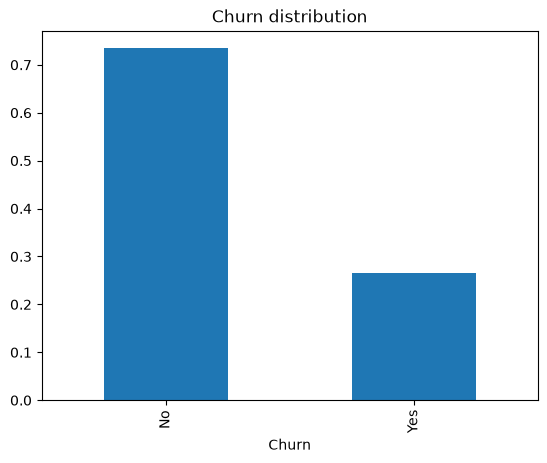

In [2]:
df["Churn"].value_counts(normalize=True).plot(kind="bar", title="Churn distribution")
plt.show()

In [3]:
# confirm the 11 blank-string rows are all tenure == 0
blank_mask = df["TotalCharges"].str.strip() == ""
df.loc[blank_mask, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

,tenure,MonthlyCharges,TotalCharges,Churn
488,0,52.55,,No
753,0,20.25,,No
936,0,80.85,,No
1082,0,25.75,,No
1340,0,56.05,,No
3331,0,19.85,,No
3826,0,25.35,,No
4380,0,20.00,,No
5218,0,19.70,,No
6670,0,73.35,,No


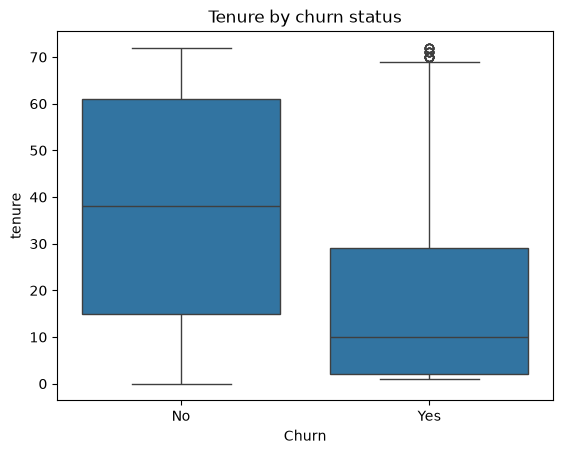

,count,mean,std,min,25%,50%,75%,max
Churn,,,,,,,,
No,5174.0,37.569965,24.113777,0.0,15.0,38.0,61.0,72.0
Yes,1869.0,17.979133,19.531123,1.0,2.0,10.0,29.0,72.0


In [4]:
sns.boxplot(data=df, x="Churn", y="tenure")
plt.title("Tenure by churn status")
plt.show()

df.groupby("Churn")["tenure"].describe()

In [5]:
df["customerID"].nunique() == len(df)  # should be True — pure identifier, no signal

True

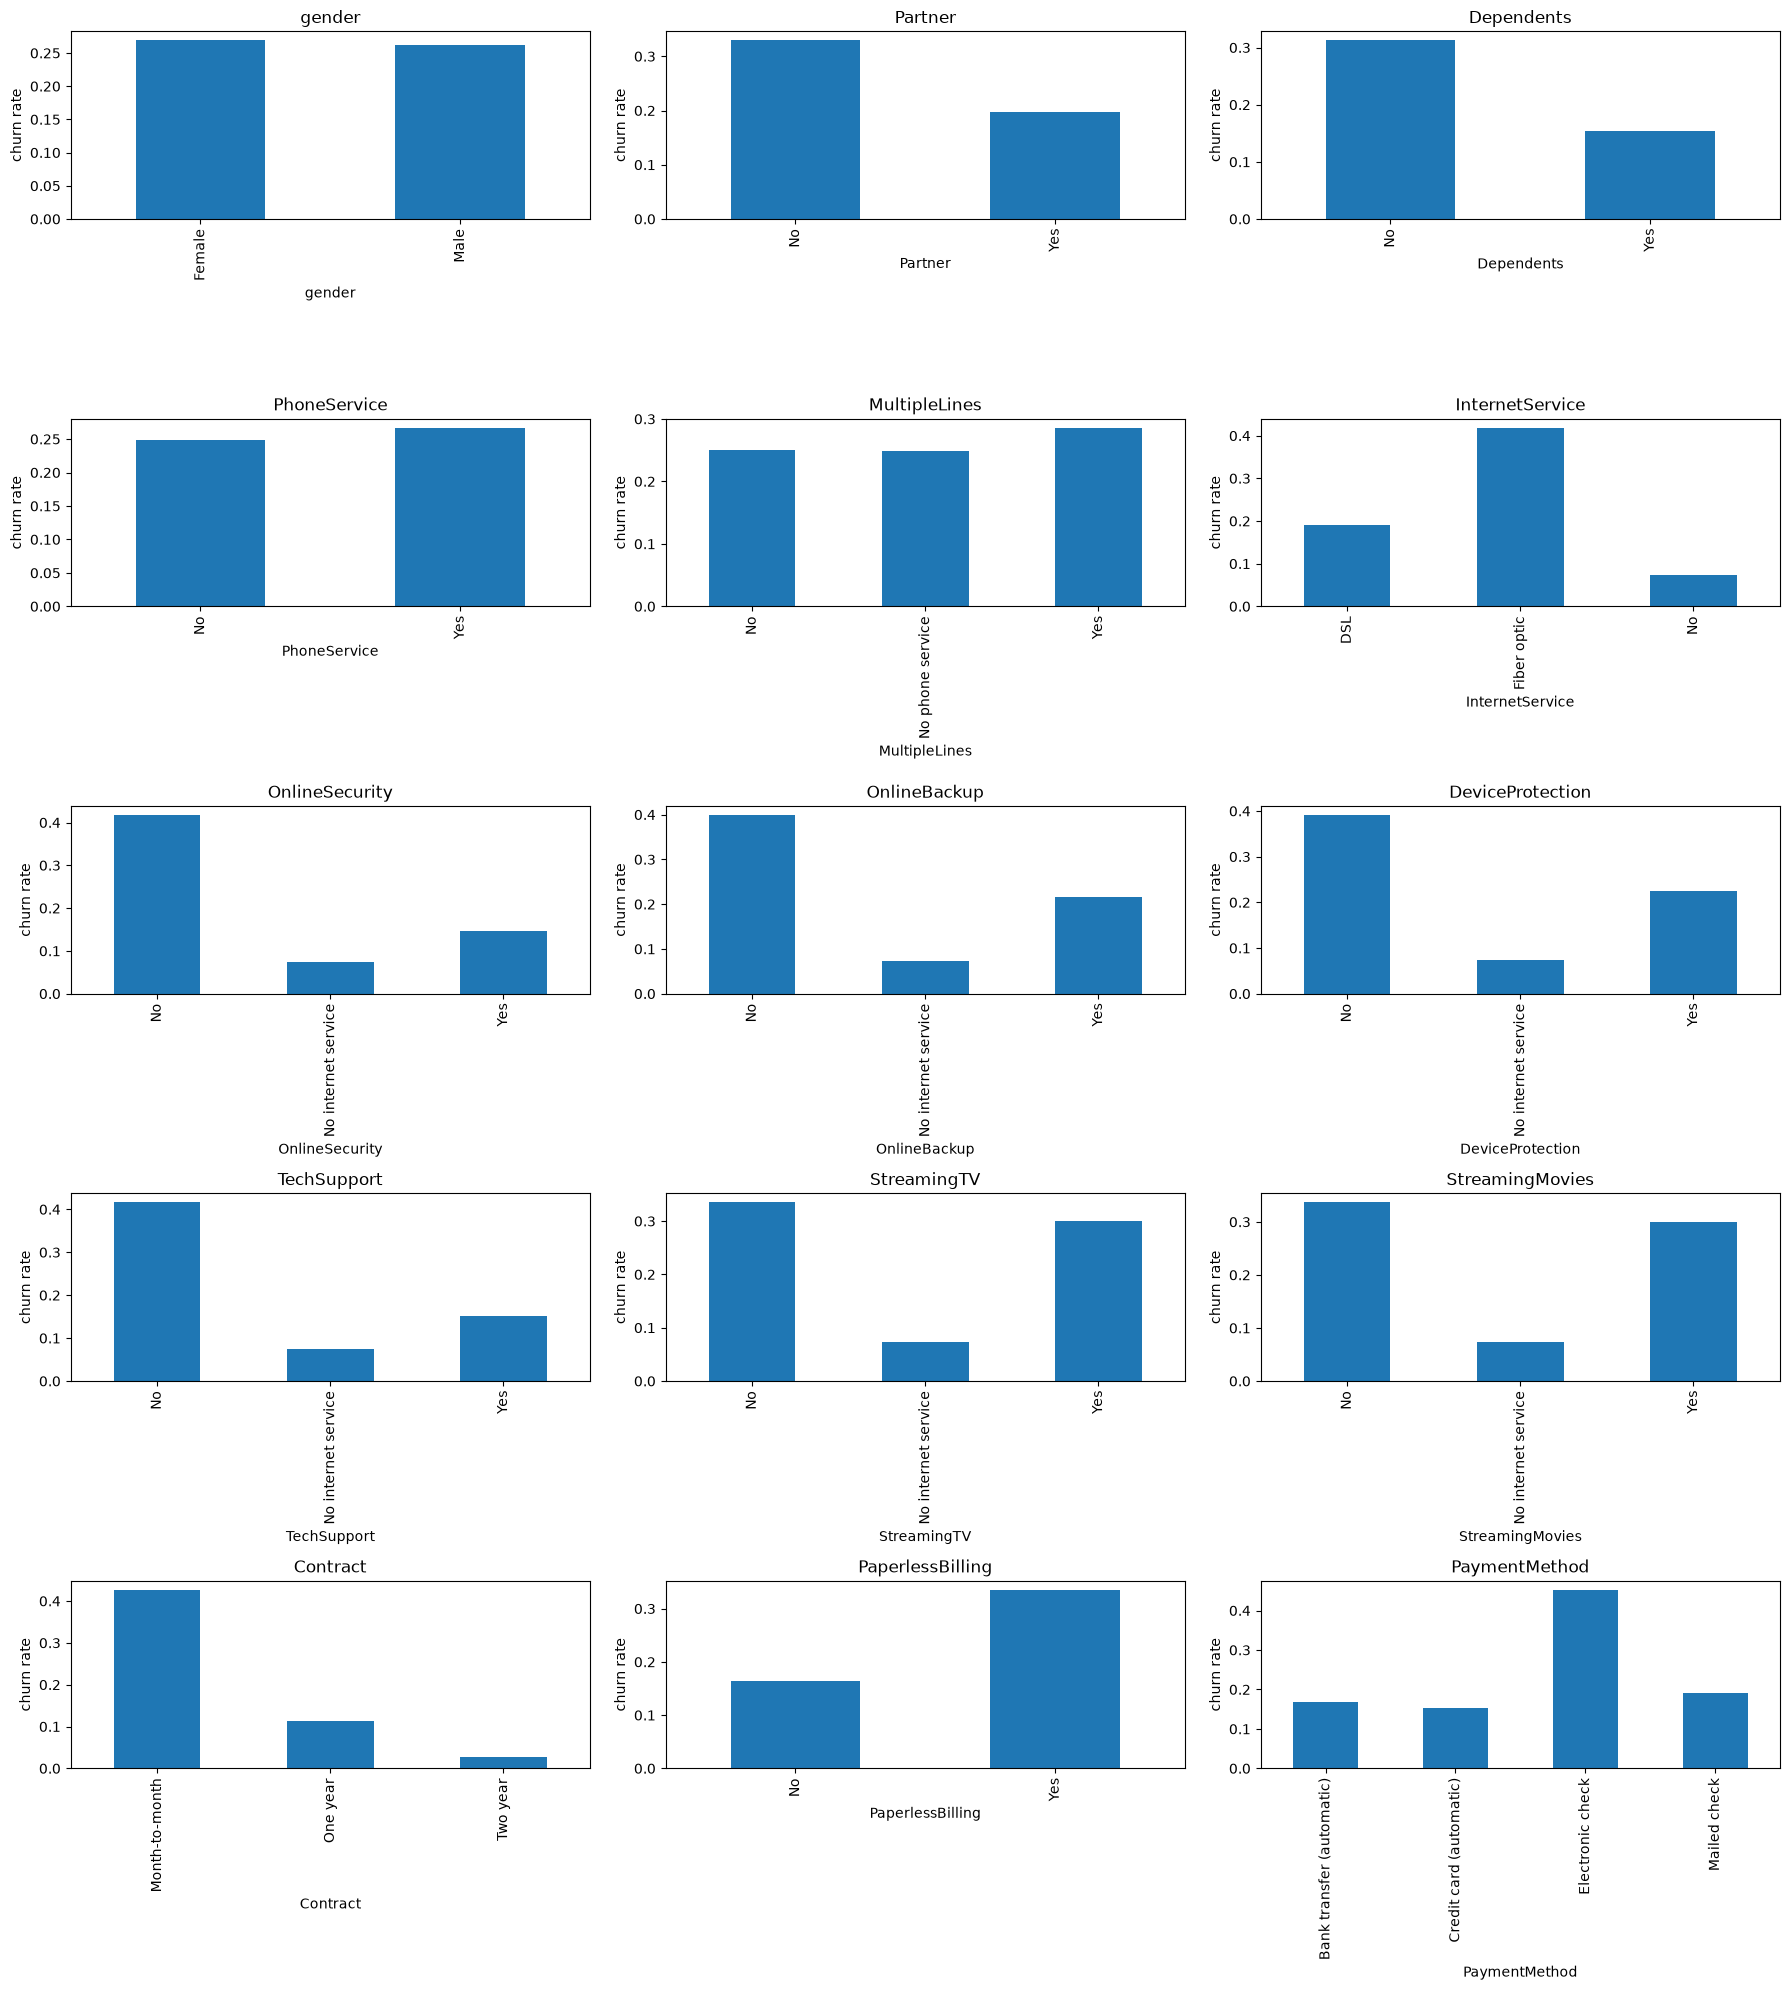

In [6]:
categorical_cols = df.select_dtypes(include="object").columns.drop(["customerID", "Churn"])

fig, axes = plt.subplots(nrows=5, ncols=3, figsize=(18, 20))
for ax, col in zip(axes.flat, categorical_cols):
    churn_rate = df.groupby(col)["Churn"].apply(lambda s: (s == "Yes").mean())
    churn_rate.plot(kind="bar", ax=ax, title=col)
    ax.set_ylabel("churn rate")
plt.tight_layout()
plt.show()

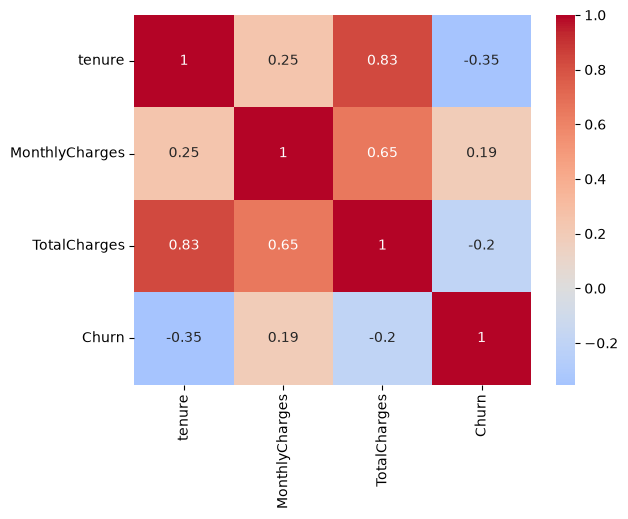

In [7]:
numeric_df = df[["tenure", "MonthlyCharges"]].copy()
numeric_df["TotalCharges"] = pd.to_numeric(df["TotalCharges"].replace(" ", "0"))
numeric_df["Churn"] = (df["Churn"] == "Yes").astype(int)

sns.heatmap(numeric_df.corr(), annot=True, cmap="coolwarm", center=0)
plt.show()

In [8]:
df.isnull().sum().sort_values(ascending=False).head()

customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64